<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FCoral-reef-health-monitoring/notebooks/Coral-reef-health/C3_Day1_Data_Preparation_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Component 3 – Day 1 (Fri 16 Oct): Data preparation
**Reef Health Monitoring – Sentinel-2 + Allen Coral Atlas + NOAA DHW**

Cell eken cell, uda idan pahalata run karanna (Shift + Enter).
Hama cell ekakatama passe **"✅ Check"** eke kiyana deya hari da balanna.

| Step | Cell | Welawa |
|---|---|---|
| 1 | Setup + login | 10 min |
| 2 | Study sites | 5 min |
| 3 | Sentinel-2 composite | 10 min |
| 4 | ACA labels (5 m → 10 m) | 5 min |
| 5 | Map eke visual check | 15 min |
| 6 | Exports start | 5 min (GEE eke 10–60 min yanawa) |
| 7 | DHW download | 5 min |
| 8 | Export status check | — |
| 9 | Samples CSV check | 10 min |


## Step 1 – Setup + login
⚠️ `PROJECT_ID` eka oyage Google Cloud / Earth Engine project ID eken replace karanna.
⚠️ Colab, Earth Engine, Google Drive **okkoma ekama Gmail account eken** login wenna ona (exports yanne e account eke Drive ekata).

In [ ]:
!pip install -q earthengine-api geemap

import ee, geemap
PROJECT_ID = 'coral-c3-2026'      # <-- meka wenas karanna (e.g. 'coral-c3-2026')

ee.Authenticate()                   # link eka click karala allow karanna
ee.Initialize(project=PROJECT_ID)

from google.colab import drive
drive.mount('/content/drive')

import os
BASE_FOLDER = 'coral_c3'                         # Drive folder name
BASE = f'/content/drive/MyDrive/{BASE_FOLDER}'
os.makedirs(BASE, exist_ok=True)
print('✅ Earth Engine OK:', ee.String('hello reef').getInfo())
print('✅ Drive folder:', BASE)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 94.0 MB/s eta 0:00:00
Mounted at /content/drive
✅ Earth Engine OK: hello reef
✅ Drive folder: /content/drive/MyDrive/coral_c3


✅ **Check:** `Earth Engine OK: hello reef` print wenna ona. Error ekak awoth (e.g. *project not registered*) error eka copy karala chat ekata dannna.

## Step 2 – Study sites
Boxes dekama approx. Step 5 eke map eke balala reef eka hariyatama box eka athule nathnam coordinates adjust karanna.
Format: `[min_lon, min_lat, max_lon, max_lat]`

In [ ]:
sites = {
    'HKD': ee.Geometry.Rectangle([80.085, 6.125, 80.110, 6.150]),   # Hikkaduwa (south-west coast)
    'PGI': ee.Geometry.Rectangle([81.175, 8.690, 81.235, 8.760]),   # Pigeon Island + Nilaveli reefs
}
# Clear-water season ekata galapena kaalaya (monsoon clouds/turbidity adu)
periods = {
    'HKD': ('2023-01-01', '2023-04-30'),   # SW coast: Dec–Apr clear
    'PGI': ('2023-05-01', '2023-09-30'),   # East coast: May–Sep clear
}
for k, g in sites.items():
    print(k, 'area ≈', round(g.area(1).getInfo() / 1e6, 2), 'km²')

HKD area ≈ 7.68 km²
PGI area ≈ 51.33 km²


✅ **Check:** site ekakata ~7 km² wage area ekak print wenawa.

## Step 3 – Sentinel-2 cloud-free composite
- `COPERNICUS/S2_SR_HARMONIZED` (Level-2A surface reflectance)
- **Cloud Score+** (`cs ≥ 0.6`) walin cloud/shadow ain karanawa
- Kaalaya athule clear pixels wala **median** eka gannawa
- NDWI > 0 walin land ain karanawa

In [ ]:
S2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
CS = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
BANDS = ['B2', 'B3', 'B4', 'B8', 'B11']

def s2_collection(aoi, start, end, cs_thresh=0.6):
    return (S2.filterBounds(aoi).filterDate(start, end)
              .linkCollection(CS, ['cs'])
              .map(lambda img: img.updateMask(img.select('cs').gte(cs_thresh))))

def s2_composite(aoi, start, end, cs_thresh=0.6):
    col = s2_collection(aoi, start, end, cs_thresh)
    img = col.select(BANDS).median().divide(10000)          # reflectance 0–1
    ndwi = img.normalizedDifference(['B3', 'B8'])
    return img.updateMask(ndwi.gt(0)).clip(aoi)              # water only

composites = {}
for k in sites:
    start, end = periods[k]
    n = s2_collection(sites[k], start, end).size().getInfo()
    composites[k] = s2_composite(sites[k], start, end)
    print(f'{k}: {n} Sentinel-2 images used ({start} → {end})')

HKD: 46 Sentinel-2 images used (2023-01-01 → 2023-04-30)
PGI: 30 Sentinel-2 images used (2023-05-01 → 2023-09-30)


✅ **Check:** site ekakata images **10–40k** wage. `0` nam dates/box eka wenas karanna.

## Step 4 – Allen Coral Atlas labels (5 m → 10 m)
ACA 5 m, Sentinel-2 10 m. 10 m pixel ekak athule ACA pixels 4k thiyena nisa **wadiyenma thiyena class eka (mode)** gannawa.
CRS = **UTM 44N (EPSG:32644)**, ethakota pixel eka hariyatama 10 m × 10 m.

| Code | Class |
|---|---|
| 11 | Sand |
| 12 | Rubble |
| 13 | Rock |
| 14 | Seagrass |
| 15 | Coral/Algae |
| 18 | Microalgal Mats |

In [ ]:
CRS = 'EPSG:32644'
proj10 = ee.Projection(CRS).atScale(10)

aca5 = ee.Image('ACA/reef_habitat/v2_0').select('benthic')
aca10 = (aca5.reduceResolution(reducer=ee.Reducer.mode(), maxPixels=16)
             .reproject(proj10)
             .toInt()
             .rename('label'))

CLASS_NAMES = {11: 'Sand', 12: 'Rubble', 13: 'Rock', 14: 'Seagrass',
               15: 'Coral/Algae', 18: 'Microalgal Mats'}

# Site ekaka class walata pixels kiyak thiyenawada (10 m)
for k, g in sites.items():
    hist = aca10.reduceRegion(ee.Reducer.frequencyHistogram(), g, 10, CRS,
                              maxPixels=1e9).get('label').getInfo() or {}
    pretty = {CLASS_NAMES.get(int(float(c)), c): int(v) for c, v in hist.items()}
    print(k, pretty)

HKD {'Sand': 527, 'Rubble': 2105, 'Rock': 1699, 'Coral/Algae': 5299}
PGI {'Sand': 1234, 'Rubble': 890, 'Rock': 3485, 'Seagrass': 23, 'Coral/Algae': 1509}


✅ **Check:** site dekatama classes kihipayak penna ona (e.g. Sand, Coral/Algae, Rock).
- `{}` (empty) nam box eka reef eka athule nehe → Step 5 map eke balala Step 2 coordinates wenas karanna.
- Class ekakata pixels **< 50** nam eka podi class ekak; eka note karaganna (presentation eke "class imbalance" widihata kiyanna puluwan).

## Step 5 – Map eke visual check
Layers on/off karala balanna (map eke udu dakuna pättē layer control eka).
1. Sentinel-2 true colour eke reef eka pena da?
2. ACA layer eka reef ekata hariyatama wäṭenawada?
3. Box eka reef eka hariyata cover karanawada?

📸 **Screenshot 2k ganna** (HKD + PGI) – presentation eke "Study area" saha "Data" slides walata.

In [ ]:
aca_vis = {'min': 11, 'max': 18,
           'palette': ['f4e4b0', 'b0a99f', '5f6b7a', '3f9c4a', 'ff7f50', '000000', '000000', '8b5a2b']}
rgb_vis = {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 0.15}

SITE_TO_SHOW = 'HKD'      # 'PGI' karala aye run karanna
centre = sites[SITE_TO_SHOW].centroid(1).coordinates().getInfo()[::-1]

m = geemap.Map(center=centre, zoom=15)
m.add_basemap('SATELLITE')
m.addLayer(composites[SITE_TO_SHOW], rgb_vis, f'S2 composite {SITE_TO_SHOW}')
m.addLayer(aca10.selfMask().clip(sites[SITE_TO_SHOW]), aca_vis, 'ACA benthic (10 m)', True, 0.6)
m.addLayer(ee.FeatureCollection([ee.Feature(sites[SITE_TO_SHOW])]).style(color='yellow', fillColor='00000000'),
           {}, 'Site box')
m

Map(center=[6.137500047213788, 80.09750000000639], controls=(WidgetControl(options=['position', 'transparent_b…

✅ **Check:** Yellow box eka athule reef eka saha colour ACA classes penawa nam hari.
Colours: sand = cream, rubble = grey, rock = dark grey, seagrass = green, coral/algae = **orange**.

## Step 6 – Exports start karanna (GEE → Google Drive)
Export 6k yanawa:
- `HKD_samples.csv`, `PGI_samples.csv` → ML training data (Dataset A)
- `S2_HKD_composite.tif`, `S2_PGI_composite.tif` → demo ekata input images
- `ACA_HKD_label.tif`, `ACA_PGI_label.tif` → label maps (map compare + passe U-Net walata)

⚠️ Me cell eka **ekaparak witharak** run karanna (dekaparak kaloth duplicate files hadenawa).

In [ ]:
tasks = []

for k in sites:
    # 1) Training samples (class ekakata 300 points, 10 m)
    stack = composites[k].addBands(aca10)
    samples = stack.stratifiedSample(
        numPoints=300, classBand='label', region=sites[k],
        scale=10, projection=CRS, geometries=True, seed=42, dropNulls=True
    ).map(lambda f: f.set('site', k))
    t = ee.batch.Export.table.toDrive(collection=samples, description=f'{k}_samples',
                                      folder=BASE_FOLDER, fileFormat='CSV')
    t.start(); tasks.append(t)

    # 2) Sentinel-2 composite GeoTIFF (int16, x10000, nodata = -9999)
    t = ee.batch.Export.image.toDrive(
        image=composites[k].multiply(10000).toInt16().unmask(-9999),
        description=f'S2_{k}_composite', folder=BASE_FOLDER,
        region=sites[k], scale=10, crs=CRS, maxPixels=1e9)
    t.start(); tasks.append(t)

    # 3) ACA label GeoTIFF (0 = no label)
    t = ee.batch.Export.image.toDrive(
        image=aca10.unmask(0).toUint8().clip(sites[k]),
        description=f'ACA_{k}_label', folder=BASE_FOLDER,
        region=sites[k], scale=10, crs=CRS, maxPixels=1e9)
    t.start(); tasks.append(t)

print('Started', len(tasks), 'export tasks')

Started 6 export tasks


✅ **Check:** `Started 6 export tasks`. Dan exports GEE eke background eke run wenawa. Colab eka close kalath prashnayak nehe. Me athara Step 7 karanna.

## Step 7 – NOAA Coral Reef Watch DHW download
DHW = Degree Heating Weeks (°C-weeks). **≥ 4 = bleaching risk, ≥ 8 = severe.**
5 km pixel eka land ekata wätunoth `NaN` enawa, e nisa code eka langa offshore pixels kihipayak try karanawa.

✅ HKD: saved (6.125, 80.075), 907 days, max DHW = 7.5
PGI (8.725, 81.225) request failed: HTTPSConnectionPool(host='pae-paha.pacioos.hawaii.edu', port=443): Read timed out. (read timeout=180)
PGI (8.725, 81.275) request failed: HTTPSConnectionPool(host='pae-paha.pacioos.hawaii.edu', port=443): Max retries exceeded with url: /erddap/griddap/dhw_5km.csv?CRW_DHW%5B(2023-01-01T12:00:00Z):1:(2025-06-30T12:00:00Z)%5D%5B(8.725):1:(8.725)%5D%5B(81.275):1:(81.275)%5D (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x78607759d810>, 'Connection to pae-paha.pacioos.hawaii.edu timed out. (connect timeout=180)'))
✅ PGI: saved (8.675, 81.225), 907 days, max DHW = 0.3


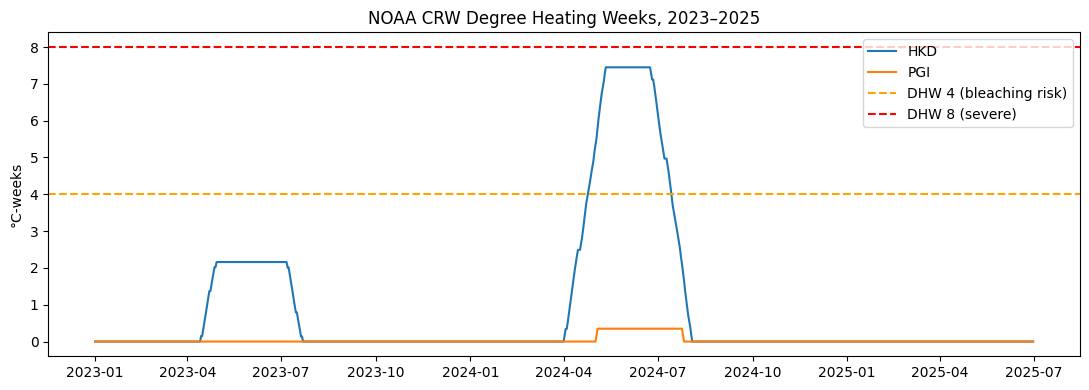

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, requests, io

ERDDAP = 'https://coastwatch.pfeg.noaa.gov/erddap/griddap/NOAA_DHW.csv'
T0, T1 = '2023-01-01T12:00:00Z', '2025-06-30T12:00:00Z'

# Langa ocean pixels (5 km grid centres), mulinma try karana eka palamu
dhw_points = {
    'HKD': [(6.125, 80.075), (6.125, 80.025), (6.175, 80.025), (6.075, 80.075)],
    'PGI': [(8.725, 81.225), (8.725, 81.275), (8.675, 81.225), (8.775, 81.225)],
}

def get_dhw(lat, lon):
    q = f'{ERDDAP}?CRW_DHW[({T0}):1:({T1})][({lat}):1:({lat})][({lon}):1:({lon})]'
    r = requests.get(q, timeout=180); r.raise_for_status()
    return pd.read_csv(io.StringIO(r.text), skiprows=[1], parse_dates=['time'])

dhw_all = {}
for k, pts in dhw_points.items():
    for lat, lon in pts:
        try:
            d = get_dhw(lat, lon)
        except Exception as e:
            print(k, (lat, lon), 'request failed:', e); continue
        if d['CRW_DHW'].notna().mean() > 0.9:
            d.to_csv(f'{BASE}/dhw_{k}.csv', index=False)
            dhw_all[k] = d
            print(f'✅ {k}: saved ({lat}, {lon}), {len(d)} days, max DHW = {d.CRW_DHW.max():.1f}')
            break
        print(k, (lat, lon), 'mostly NaN (land pixel) – trying next')

fig, ax = plt.subplots(figsize=(11, 4))
for k, d in dhw_all.items():
    ax.plot(d['time'], d['CRW_DHW'], label=k)
ax.axhline(4, ls='--', c='orange', label='DHW 4 (bleaching risk)')
ax.axhline(8, ls='--', c='red', label='DHW 8 (severe)')
ax.set_ylabel('°C-weeks'); ax.set_title('NOAA CRW Degree Heating Weeks, 2023–2025'); ax.legend()
plt.tight_layout(); plt.savefig(f'{BASE}/dhw_plot.png', dpi=150); plt.show()

✅ **Check:** `dhw_HKD.csv`, `dhw_PGI.csv`, `dhw_plot.png` Drive eke `coral_c3` folder eke thiyenna ona.
2024 April–June wage kaalayedi DHW peak ekak penna ona (2024 global bleaching event). Me plot eka presentation slide ekakata ganna.

`request failed` / timeout nam: minithu 5kin aye run karanna (NOAA server eka samaharawita slow).

## Step 8 – Export status check
Me cell eka minithu 5–10kata sarayak run karanna, okkoma `COMPLETED` wenakan.
(GEE Code Editor → **Tasks** tab eken bath balanna puluwan.)

In [ ]:
for t in tasks:
    s = t.status()
    print(f"{s['description']:<22} {s['state']:<10} {s.get('error_message', '')}")

✅ **Check:** 6ma `COMPLETED`. `FAILED` ekak nam error message eka chat ekata copy karanna.

## Step 9 – Samples CSV check (exports iwara unata passe)
Drive sync wenna minithu 1–2k yanna puluwan. File not found awoth tikak inna.

['ACA_HKD_label.tif', 'ACA_PGI_label.tif', 'HKD_samples.csv', 'PGI_samples.csv', 'S2_HKD_composite.tif', 'S2_PGI_composite.tif', 'dhw_HKD.csv', 'dhw_PGI.csv', 'dhw_plot.png']

Total samples: 2424
class_name  Coral/Algae  Rock  Rubble  Sand  Seagrass
site                                                 
HKD                 300   300     300   300         0
PGI                 300   300     300   300        24

Band statistics (reflectance):
              B2         B3         B4         B8        B11
count  2424.0000  2424.0000  2424.0000  2424.0000  2424.0000
mean      0.0936     0.1069     0.0791     0.0600     0.0552
std       0.0276     0.0323     0.0346     0.0286     0.0324
min       0.0385     0.0429     0.0258     0.0202     0.0204
25%       0.0738     0.0858     0.0522     0.0357     0.0276
50%       0.0870     0.0966     0.0767     0.0572     0.0485
75%       0.1070     0.1230     0.0952     0.0744     0.0776
max       0.2966     0.2889     0.2542     0.1994     0.2571


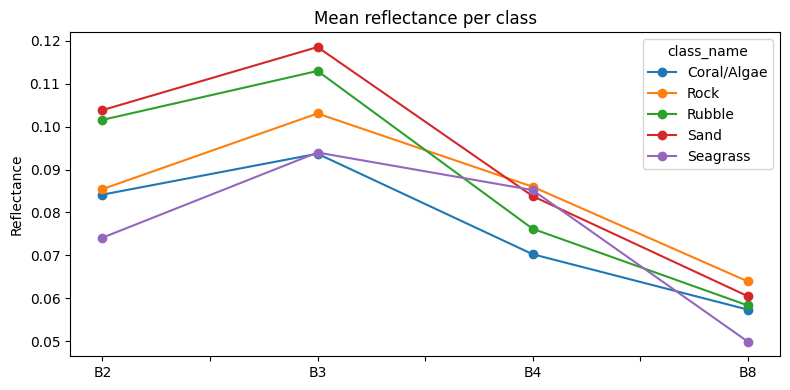

In [ ]:
import pandas as pd, matplotlib.pyplot as plt
import json, glob
print(sorted(os.path.basename(f) for f in glob.glob(f'{BASE}/*')))

df = pd.concat([pd.read_csv(f'{BASE}/{k}_samples.csv') for k in sites], ignore_index=True)
df['class_name'] = df['label'].map(CLASS_NAMES)
print('\nTotal samples:', len(df))
print(df.groupby(['site', 'class_name']).size().unstack(fill_value=0))

print('\nBand statistics (reflectance):')
print(df[['B2', 'B3', 'B4', 'B8', 'B11']].describe().round(4))

# Class ekaka mean spectrum – classes wenas da kiyala balanna
spec = df.groupby('class_name')[['B2', 'B3', 'B4', 'B8']].mean()
spec.T.plot(marker='o', figsize=(8, 4), title='Mean reflectance per class')
plt.ylabel('Reflectance'); plt.tight_layout()
plt.savefig(f'{BASE}/class_spectra.png', dpi=150); plt.show()

✅ **Check (ada dawase final result eka):**
- Samples **~1,500–3,600** wage
- B2/B3 values **0.02–0.15** athara (wadiya 0.3+ nam cloud/glint ithuru wela)
- `class_spectra.png` eke sand eka (brightest) saha coral/algae/seagrass (darker) wenas wenawa penawa nam **data eka model training walata ready** 🎉

**Me output tika chat ekata dannna:** Step 3 image counts, Step 4 class counts, Step 9 table eka saha `class_spectra.png`. Ita passe hete (Sat 17) model 3 train karamu.